In [2]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("../reviews.db")

df = pd.read_sql_query("SELECT * FROM review", conn)

df.head()

,id,source,product_name,rating,review_title,review_text,review_date,review_language,sentiment_label,topic_label,generated_response
0,1,Ozon,Беспроводная мышь,5,Отлично,Очень хорошее качество и быстрая доставка,2026-04-01 00:00:00.000000,ru,None,None,None
1,2,Wildberries,Зарядное устройство,2,Разочарован,Зарядка перестала работать через два дня,2026-04-02 00:00:00.000000,ru,None,None,None
2,3,Ozon,Наушники Bluetooth,4,Хороший товар,"Звук хороший, но доставка была немного медленной",2026-04-03 00:00:00.000000,ru,None,None,None
3,4,Яндекс Маркет,Кофемашина,1,Очень плохо,"Товар пришёл сломанный, очень разочарован",2026-04-04 00:00:00.000000,ru,None,None,None


In [3]:
df.shape

(4, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  4 non-null      int64 
 1   source              4 non-null      str   
 2   product_name        4 non-null      str   
 3   rating              4 non-null      int64 
 4   review_title        4 non-null      str   
 5   review_text         4 non-null      str   
 6   review_date         4 non-null      str   
 7   review_language     4 non-null      str   
 8   sentiment_label     0 non-null      object
 9   topic_label         0 non-null      object
 10  generated_response  0 non-null      object
dtypes: int64(2), object(3), str(6)
memory usage: 484.0+ bytes


In [5]:
df["rating"].value_counts().sort_index()

rating
1    1
2    1
4    1
5    1
Name: count, dtype: int64

In [6]:
df["source"].value_counts()

source
Ozon             2
Wildberries      1
Яндекс Маркет    1
Name: count, dtype: int64

In [7]:
df["text_length"] = df["review_text"].apply(len)
df[["review_text", "text_length"]]

,review_text,text_length
0,Очень хорошее качество и быстрая доставка,41
1,Зарядка перестала работать через два дня,40
2,"Звук хороший, но доставка была немного медленной",48
3,"Товар пришёл сломанный, очень разочарован",41


In [8]:
df["text_length"].describe()

count     4.000000
mean     42.500000
std       3.696846
min      40.000000
25%      40.750000
50%      41.000000
75%      42.750000
max      48.000000
Name: text_length, dtype: float64

In [9]:
import re

def clean_text(text):
    if pd.isna(text):
        return ""
    
    text = text.lower().strip()
    text = re.sub(r"[^\w\sа-яА-ЯёЁ]", "", text)
    text = re.sub(r"\s+", " ", text)
    
    return text

df["clean_text"] = df["review_text"].apply(clean_text)

df[["review_text", "clean_text"]]

,review_text,clean_text
0,Очень хорошее качество и быстрая доставка,очень хорошее качество и быстрая доставка
1,Зарядка перестала работать через два дня,зарядка перестала работать через два дня
2,"Звук хороший, но доставка была немного медленной",звук хороший но доставка была немного медленной
3,"Товар пришёл сломанный, очень разочарован",товар пришёл сломанный очень разочарован


In [10]:
df.isnull().sum()

id                    0
source                0
product_name          0
rating                0
review_title          0
review_text           0
review_date           0
review_language       0
sentiment_label       4
topic_label           4
generated_response    4
text_length           0
clean_text            0
dtype: int64

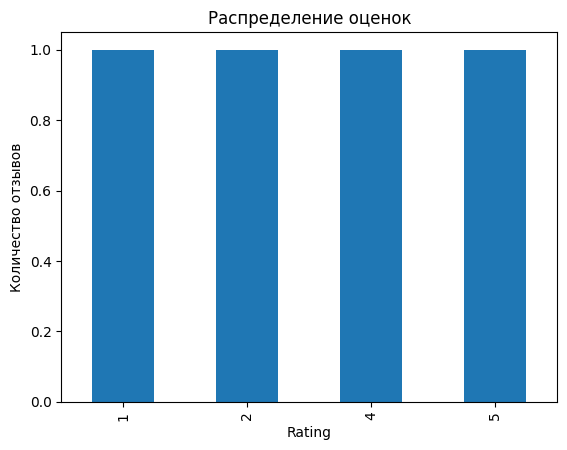

In [12]:
import matplotlib.pyplot as plt

df["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Распределение оценок")
plt.xlabel("Rating")
plt.ylabel("Количество отзывов")
plt.show()

In [13]:
def get_sentiment(rating):
    if rating >= 4:
        return "положительный"
    elif rating <= 2:
        return "отрицательный"
    else:
        return "нейтральный"

df["sentiment_label"] = df["rating"].apply(get_sentiment)

df[["rating", "sentiment_label"]]

,rating,sentiment_label
0,5,положительный
1,2,отрицательный
2,4,положительный
3,1,отрицательный


In [14]:
df["sentiment_label"].value_counts()

sentiment_label
положительный    2
отрицательный    2
Name: count, dtype: int64

In [15]:
def detect_topic(text):
    text = text.lower()
    
    if "достав" in text:
        return "доставка"
    elif "слом" in text or "работ" in text:
        return "проблема_с_товаром"
    elif "звук" in text:
        return "качество_товара"
    else:
        return "другое"

df["topic_label"] = df["clean_text"].apply(detect_topic)

df[["clean_text", "topic_label"]]

,clean_text,topic_label
0,очень хорошее качество и быстрая доставка,доставка
1,зарядка перестала работать через два дня,проблема_с_товаром
2,звук хороший но доставка была немного медленной,доставка
3,товар пришёл сломанный очень разочарован,проблема_с_товаром


In [16]:
df_ml = df[["clean_text", "sentiment_label"]].copy()
df_ml

,clean_text,sentiment_label
0,очень хорошее качество и быстрая доставка,положительный
1,зарядка перестала работать через два дня,отрицательный
2,звук хороший но доставка была немного медленной,положительный
3,товар пришёл сломанный очень разочарован,отрицательный


In [17]:
label_map = {
    "положительный": 1,
    "отрицательный": 0
}

df_ml["label"] = df_ml["sentiment_label"].map(label_map)

df_ml

,clean_text,sentiment_label,label
0,очень хорошее качество и быстрая доставка,положительный,1
1,зарядка перестала работать через два дня,отрицательный,0
2,звук хороший но доставка была немного медленной,положительный,1
3,товар пришёл сломанный очень разочарован,отрицательный,0


In [18]:
from datasets import Dataset

dataset = Dataset.from_pandas(df_ml)
dataset

Dataset({
    features: ['clean_text', 'sentiment_label', 'label'],
    num_rows: 4
})

In [19]:
from transformers import AutoTokenizer

model_name = "DeepPavlov/rubert-base-cased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

c:\Users\kubad\Documents\marketplace\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kubad\.cache\huggingface\hub\models--DeepPavlov--rubert-base-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [20]:
def tokenize(example):
    return tokenizer(example["clean_text"], padding="max_length", truncation=True)

dataset = dataset.map(tokenize)

Map:   0%|          | 0/4 [00:00<?, ? examples/s]

In [21]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

pytorch_model.bin:   0%|          | 0.00/714M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

In [22]:
from transformers import pipeline

classifier = pipeline(
    "sentiment-analysis",
    model=model_name
)

classifier("Очень хороший продукт")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you

[{'label': 'LABEL_1', 'score': 0.5991872549057007}]

In [23]:
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="sberbank-ai/rugpt3small_based_on_gpt2"
)

config.json:   0%|          | 0.00/720 [00:00<?, ?B/s]

c:\Users\kubad\Documents\marketplace\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kubad\.cache\huggingface\hub\models--sberbank-ai--rugpt3small_based_on_gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin:   0%|          | 0.00/551M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: sberbank-ai/rugpt3small_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/574 [00:00<?, ?B/s]

In [24]:
def create_prompt(review, sentiment):
    if sentiment == "положительный":
        return f"Ответь на положительный отзыв клиента: {review}"
    else:
        return f"Ответь на негативный отзыв клиента, извинись и предложи помощь: {review}"

In [25]:
review = df.iloc[0]["review_text"]
sentiment = df.iloc[0]["sentiment_label"]

prompt = create_prompt(review, sentiment)

result = generator(prompt, max_length=100)

print(result[0]["generated_text"])

Passing `generation_config` together with generation-related arguments=({'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Ответь на положительный отзыв клиента: Очень хорошее качество и быстрая доставка!  Спасибо!  Удачи в работе! 
 Ответ: Выбрал товар на сайте, а на сайте его нет.  На сайте все есть.  Спасибо!  Удачи в работе! 
 Ответ: Здравствуйте, Елена!  Спасибо за оперативность и оперативность в работе магазина.  Ваша претензия не была удовлетворена.  Спасибо! 
 Ответ: Здравствуйте, Надежда!  Спасибо за оперативность и оперативность в работе магазина.  Ваша претензия не была удовлетворена.  Спасибо! 
 Ответ: Здравствуйте, Екатерина!  Спасибо за оперативность и оперативность в работе магазина.  Ваша претензия не была удовлетворена.  Спасибо! 
 Ответ: Спасибо за оперативность и оперативность в работе магазина.  Ваша претензия не была удовлетворена.  Спасибо! 
 Ответ: Здравствуйте, Екатерина!  Спасибо за оперативность и оперативность в работе магазина.  Ваша претензия не была удовлетворена.  Спасибо! 
 Ответ: Здравствуйте, Елена!  Спасибо за оперативность и оперативность в работе магазина.  Ваша претенз

In [26]:
def generate_response(review, sentiment):
    if sentiment == "положительный":
        return f"Спасибо за ваш отзыв! Мы рады, что вам понравился товар."
    else:
        return f"Нам очень жаль, что вы столкнулись с проблемой. Пожалуйста, свяжитесь с нашей поддержкой."

In [27]:
df["generated_response"] = df.apply(
    lambda row: generate_response(row["review_text"], row["sentiment_label"]),
    axis=1
)

df[["review_text", "generated_response"]]

,review_text,generated_response
0,Очень хорошее качество и быстрая доставка,"Спасибо за ваш отзыв! Мы рады, что вам понрави..."
1,Зарядка перестала работать через два дня,"Нам очень жаль, что вы столкнулись с проблемой..."
2,"Звук хороший, но доставка была немного медленной","Спасибо за ваш отзыв! Мы рады, что вам понрави..."
3,"Товар пришёл сломанный, очень разочарован","Нам очень жаль, что вы столкнулись с проблемой..."


In [28]:
knowledge_base = [
    "Возврат товара возможен в течение 14 дней после покупки.",
    "Если товар поврежден, клиент может получить замену или возврат средств.",
    "Доставка обычно занимает от 2 до 5 дней.",
    "Гарантия на товар составляет 1 год."
]

In [29]:
from sentence_transformers import SentenceTransformer

In [30]:
model_embed = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

c:\Users\kubad\Documents\marketplace\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kubad\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [31]:
from sentence_transformers import SentenceTransformer

model_embed = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

kb_embeddings = model_embed.encode(knowledge_base)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [32]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def retrieve_context(query):
    query_embedding = model_embed.encode([query])
    
    similarities = cosine_similarity(query_embedding, kb_embeddings)
    
    best_idx = np.argmax(similarities)
    
    return knowledge_base[best_idx]

In [33]:
retrieve_context("товар сломанный")

'Если товар поврежден, клиент может получить замену или возврат средств.'

In [34]:
def generate_rag_response(review, sentiment):
    context = retrieve_context(review)
    
    if sentiment == "положительный":
        return f"Спасибо за отзыв! {context}"
    else:
        return f"Нам жаль, что возникла проблема. {context}"

In [35]:
df["rag_response"] = df.apply(
    lambda row: generate_rag_response(row["review_text"], row["sentiment_label"]),
    axis=1
)

df[["review_text", "rag_response"]]

,review_text,rag_response
0,Очень хорошее качество и быстрая доставка,Спасибо за отзыв! Доставка обычно занимает от ...
1,Зарядка перестала работать через два дня,"Нам жаль, что возникла проблема. Возврат товар..."
2,"Звук хороший, но доставка была немного медленной",Спасибо за отзыв! Доставка обычно занимает от ...
3,"Товар пришёл сломанный, очень разочарован","Нам жаль, что возникла проблема. Если товар по..."


In [36]:
df[["review_text", "rating", "sentiment_label"]]

,review_text,rating,sentiment_label
0,Очень хорошее качество и быстрая доставка,5,положительный
1,Зарядка перестала работать через два дня,2,отрицательный
2,"Звук хороший, но доставка была немного медленной",4,положительный
3,"Товар пришёл сломанный, очень разочарован",1,отрицательный


In [37]:
df[["review_text", "topic_label"]]

,review_text,topic_label
0,Очень хорошее качество и быстрая доставка,доставка
1,Зарядка перестала работать через два дня,проблема_с_товаром
2,"Звук хороший, но доставка была немного медленной",доставка
3,"Товар пришёл сломанный, очень разочарован",проблема_с_товаром


In [38]:
df[["review_text", "generated_response", "rag_response"]]

,review_text,generated_response,rag_response
0,Очень хорошее качество и быстрая доставка,"Спасибо за ваш отзыв! Мы рады, что вам понрави...",Спасибо за отзыв! Доставка обычно занимает от ...
1,Зарядка перестала работать через два дня,"Нам очень жаль, что вы столкнулись с проблемой...","Нам жаль, что возникла проблема. Возврат товар..."
2,"Звук хороший, но доставка была немного медленной","Спасибо за ваш отзыв! Мы рады, что вам понрави...",Спасибо за отзыв! Доставка обычно занимает от ...
3,"Товар пришёл сломанный, очень разочарован","Нам очень жаль, что вы столкнулись с проблемой...","Нам жаль, что возникла проблема. Если товар по..."


In [39]:
def evaluate_response(row):
    if row["sentiment_label"] == "положительный" and "Спасибо" in row["rag_response"]:
        return "good"
    elif row["sentiment_label"] == "отрицательный" and "жаль" in row["rag_response"]:
        return "good"
    else:
        return "bad"

df["response_quality"] = df.apply(evaluate_response, axis=1)

df["response_quality"].value_counts()

response_quality
good    4
Name: count, dtype: int64